# EJECT! -- Ballistic Trajectory Simulation for Volcanic Eruptions with Topography

This notebook demonstrates how to calculate ballistic trajectories that account for the actual topography of a volcano. We'll use the Ruapehu volcano (New Zealand) topography data included with the simulation.


### References
If you use this work, please cite the original sources:

Original Visual Basic implementation: Mastin, L.G. (2001). A simple calculator of ballistic trajectories for blocks ejected during volcanic eruptions. U.S. Geological Survey Open-File Report 01-45, 16p. https://pubs.usgs.gov/of/2001/0045/

MATLAB translation: Strehlow, K., Mastin, L.G., Sandri, L., Gottsmann, J.H., Kilgour, G., Rust, A.C., & Tonini, R. (2019). Eject! for Matlab. https://vhub.org/resources/4543

### Overview

Instead of assuming a flat landing plane, this example:
1. Calculates ballistic trajectories in multiple directions
2. Compares the trajectory with the actual topographic profile
3. Determines where the projectile actually impacts the volcano slope
4. Visualizes the results with topography overlays

### Required installed libraries for this workflow

In [1]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from eject import eject

# Set up matplotlib
plt.style.use('seaborn-v0_8-darkgrid')
%matplotlib inline
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['font.size'] = 11

print("✓ Libraries imported successfully!")

✓ Libraries imported successfully!


## Step 1: Load and Visualize Topography Data

The topography file contains elevation profiles in four directions (North, South, East, West) from the Ruapehu crater.

In [2]:
# Load topography data
topography_file = 'Topography.xlsx'
df = pd.read_excel(topography_file, sheet_name='Ruapehu')

print("Topography data loaded!")
print(f"\nData shape: {df.shape}")
print(f"\nColumns: {df.columns.tolist()}")
print(f"\nFirst few rows:")
print(df.head(10))

Topography data loaded!

Data shape: (65, 8)

Columns: ['x_east', 'topography_east', 'x_north', 'topography_north', 'x_west', 'topography_west', 'x_south', 'topography_south']

First few rows:
    x_east  topography_east  x_north  topography_north   x_west  \
0    0.000           2380.0    0.000            2380.0    0.000   
1  250.000           2540.0  265.625            2540.0  250.000   
2  296.875           2560.0  281.250            2560.0  281.250   
3  312.500           2580.0  312.500            2580.0  296.875   
4  343.750           2600.0  406.250            2600.0  312.500   
5  406.250           2600.0  500.000            2620.0  437.500   
6  437.500           2580.0  546.875            2640.0  500.000   
7  484.375           2560.0  671.875            2640.0  562.500   
8  515.625           2540.0  781.250            2620.0  593.750   
9  562.500           2520.0  906.250            2600.0  656.250   

   topography_west  x_south  topography_south  
0           2380.0   

In [3]:
# Extract topography profiles for each direction
directions = {
    'East': {'x': df['x_east'].dropna().values, 'z': df['topography_east'].dropna().values},
    'West': {'x': df['x_west'].dropna().values, 'z': df['topography_west'].dropna().values},
    'North': {'x': df['x_north'].dropna().values, 'z': df['topography_north'].dropna().values},
    'South': {'x': df['x_south'].dropna().values, 'z': df['topography_south'].dropna().values}
}

# Vent elevation (crater lake elevation)
vent_elevation = 2380  # meters above sea level

# Convert topography so vent is at z=0
for direction in directions:
    directions[direction]['z'] = directions[direction]['z'] - vent_elevation

print(f"✓ Topography profiles extracted for {len(directions)} directions")
print(f"\nVent elevation: {vent_elevation} m above sea level")
print(f"All elevations adjusted so vent is at z=0")

✓ Topography profiles extracted for 4 directions

Vent elevation: 2380 m above sea level
All elevations adjusted so vent is at z=0


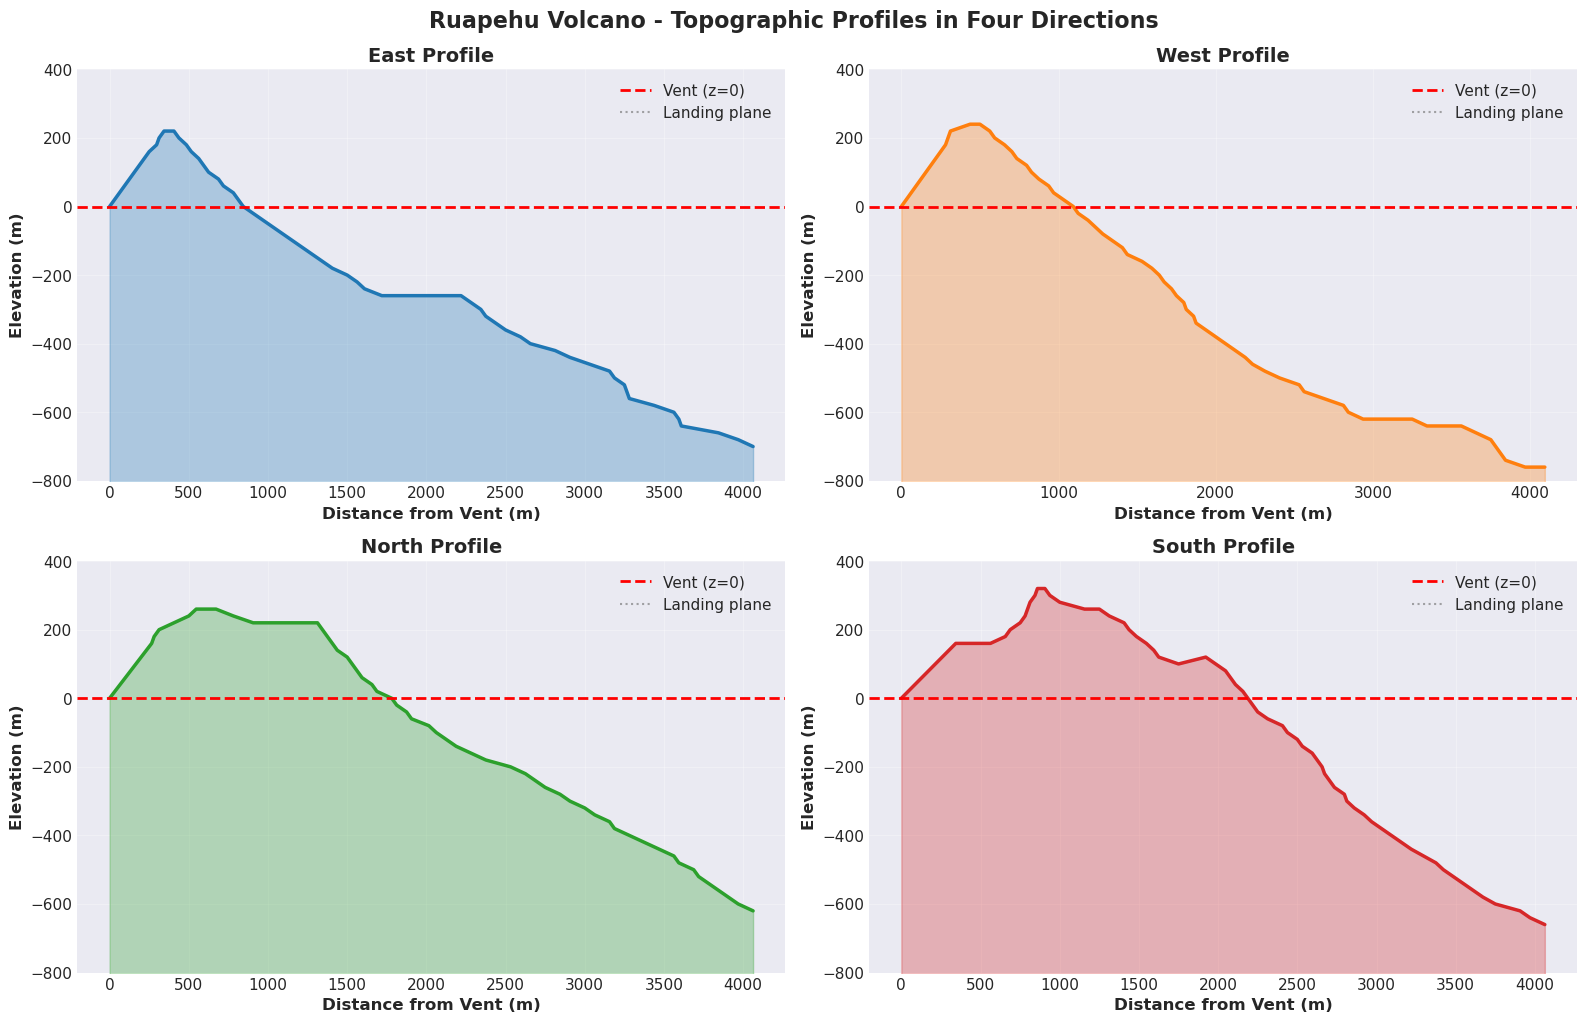


✓ Topography profiles plotted!


In [5]:
# Plot all topography profiles
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

colors = {'East': '#1f77b4', 'West': '#ff7f0e', 'North': '#2ca02c', 'South': '#d62728'}

for idx, (dir_name, data) in enumerate(directions.items()):
    ax = axes[idx]
    ax.plot(data['x'], data['z'], linewidth=2.5, color=colors[dir_name])
    ax.fill_between(data['x'], data['z'], -1500, alpha=0.3, color=colors[dir_name])
    ax.axhline(y=0, color='red', linestyle='--', linewidth=2, label='Vent (z=0)')
    ax.axhline(y=-1000, color='gray', linestyle=':', linewidth=1.5, alpha=0.7, label='Landing plane')
    ax.set_xlabel('Distance from Vent (m)', fontsize=12, fontweight='bold')
    ax.set_ylabel('Elevation (m)', fontsize=12, fontweight='bold')
    ax.set_title(f'{dir_name} Profile', fontsize=14, fontweight='bold')
    ax.grid(True, alpha=0.3)
    ax.legend()
    ax.set_ylim(-800, 400)

plt.tight_layout()
plt.suptitle('Ruapehu Volcano - Topographic Profiles in Four Directions', 
             fontsize=16, fontweight='bold', y=1.02)
plt.show()

print("\n✓ Topography profiles plotted!")

## Step 2: Calculate a Trajectory and Find Impact Point

Now let's calculate a trajectory and determine where it actually impacts the volcano slope, rather than just where it crosses the landing plane at z=-1000m.

In [6]:
def find_impact_point(traj_x, traj_z, topo_x, topo_z):
    """
    Find where a trajectory intersects with topography.
    
    Args:
        traj_x: trajectory x-coordinates
        traj_z: trajectory z-coordinates
        topo_x: topography x-coordinates
        topo_z: topography z-coordinates
    
    Returns:
        impact_x: x-coordinate of impact
        impact_z: z-coordinate of impact
    """
    # Create interpolation function for topography
    topo_interp = interp1d(topo_x, topo_z, kind='linear', 
                           bounds_error=False, fill_value='extrapolate')
    
    # Find where trajectory crosses topography
    for i in range(1, len(traj_z)):
        topo_height = topo_interp(traj_x[i])
        if traj_z[i] < topo_height:
            # Linear interpolation for more accurate impact point
            impact_x = traj_x[i-1] + (traj_x[i] - traj_x[i-1]) / 2
            impact_z = traj_z[i-1] + (traj_z[i] - traj_z[i-1]) / 2
            return impact_x, impact_z
    
    # If no intersection found, return last point
    return traj_x[-1], traj_z[-1]

print("✓ Impact detection function defined")

✓ Impact detection function defined


In [7]:
# Calculate a sample trajectory
angle = 45.0      # degrees
velocity = 100.0  # m/s
diameter = 0.5    # m

print(f"Calculating trajectory with:")
print(f"  Angle: {angle}°")
print(f"  Velocity: {velocity} m/s")
print(f"  Diameter: {diameter} m")
print()

traj = eject(angle, velocity, diameter)
traj_x = traj[:, 0]
traj_z = traj[:, 1]

print(f"✓ Trajectory calculated")
print(f"  Landing plane distance: {traj_x[-1]:.1f} m")
print(f"  Maximum height: {np.max(traj_z):.1f} m")

Calculating trajectory with:
  Angle: 45.0°
  Velocity: 100.0 m/s
  Diameter: 0.5 m

✓ Trajectory calculated
  Landing plane distance: 1220.9 m
  Maximum height: 227.7 m


## Step 3: Compare Trajectory with Topography in Each Direction

We'll overlay the same trajectory on each topographic profile to see where it would land in different directions.

In [8]:
# Calculate impact points for each direction
impact_points = {}

print("Finding impact points in each direction:\n")
print(f"{'Direction':<10} {'Landing Plane':<15} {'Topography':<15} {'Difference'}")
print("-" * 65)

for dir_name, data in directions.items():
    impact_x, impact_z = find_impact_point(traj_x, traj_z, data['x'], data['z'])
    impact_points[dir_name] = {'x': impact_x, 'z': impact_z}
    
    landing_plane_dist = traj_x[-1]
    difference = impact_x - landing_plane_dist
    
    print(f"{dir_name:<10} {landing_plane_dist:>10.1f} m    {impact_x:>10.1f} m    {difference:>+9.1f} m")

print("\n✓ Impact points calculated for all directions")

Finding impact points in each direction:

Direction  Landing Plane   Topography      Difference
-----------------------------------------------------------------
East           1220.9 m         339.4 m       -881.4 m
West           1220.9 m         302.2 m       -918.6 m
North          1220.9 m         442.3 m       -778.6 m
South          1220.9 m         620.3 m       -600.6 m

✓ Impact points calculated for all directions


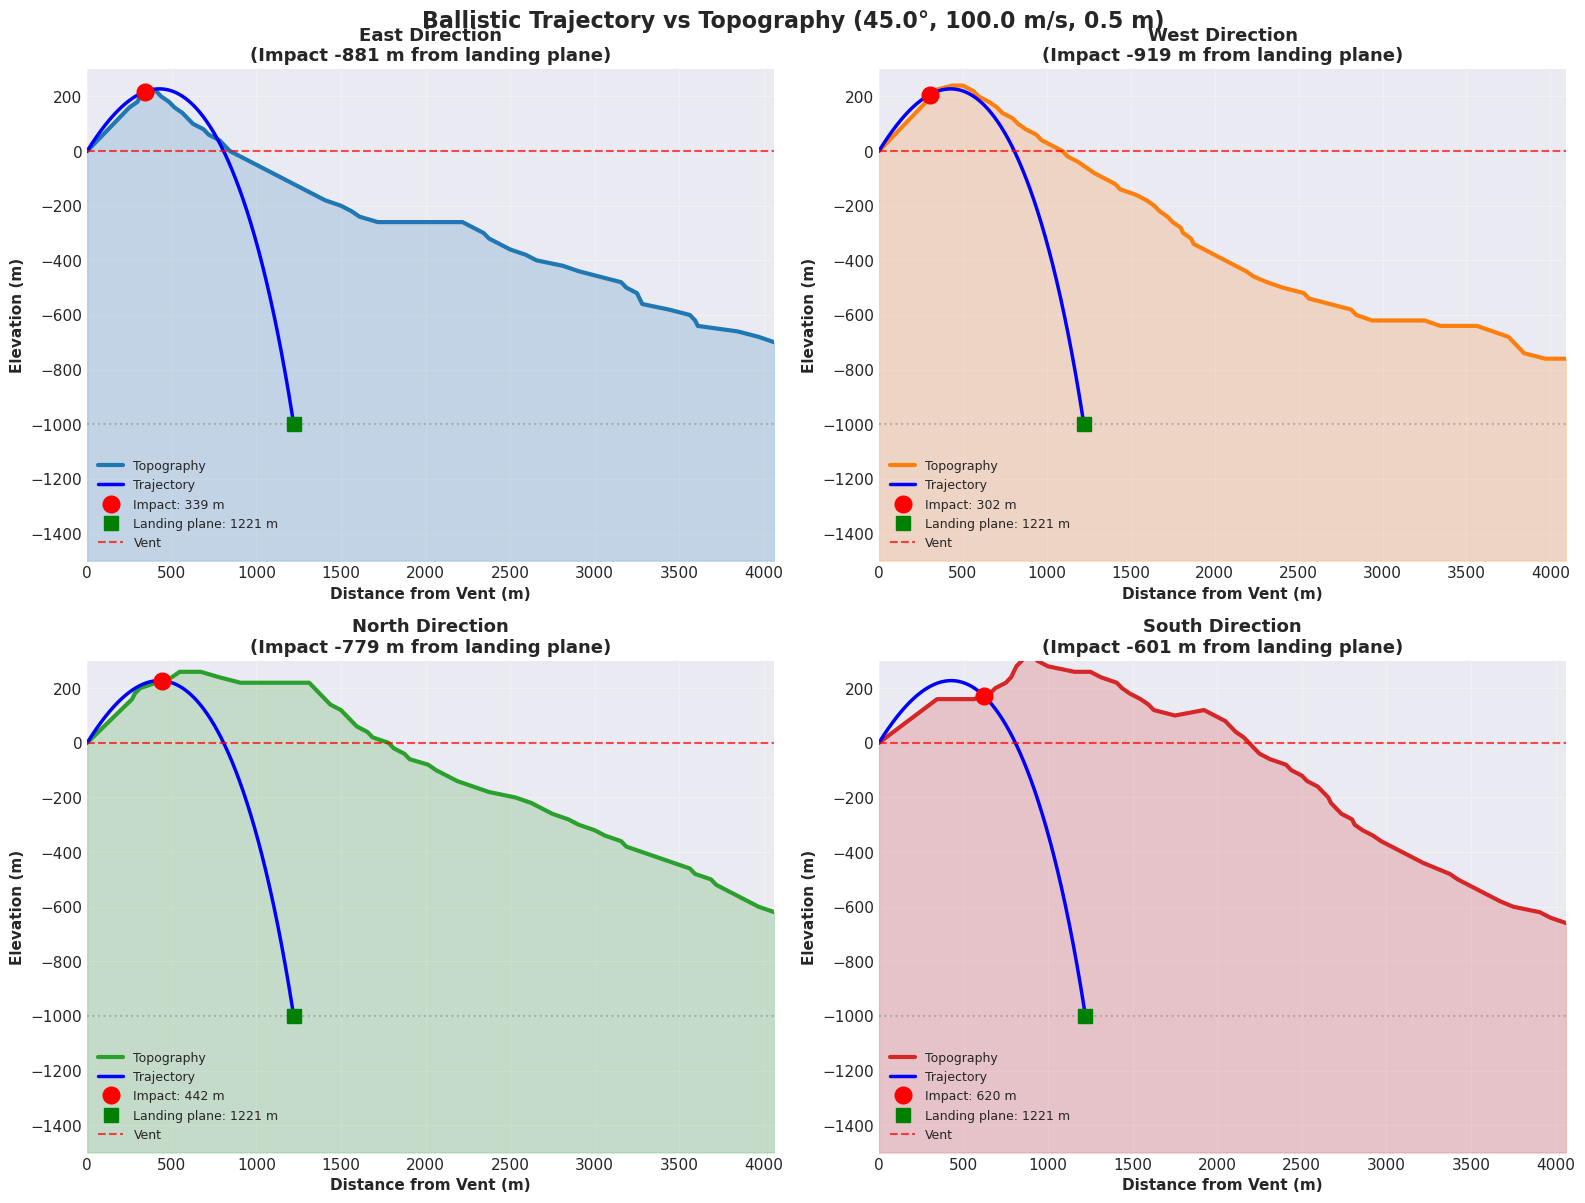


✓ Trajectory-topography comparison plots complete!


In [9]:
# Create detailed plots for each direction
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for idx, (dir_name, data) in enumerate(directions.items()):
    ax = axes[idx]
    
    # Plot topography
    ax.plot(data['x'], data['z'], linewidth=3, color=colors[dir_name], 
            label='Topography', zorder=1)
    ax.fill_between(data['x'], data['z'], -1500, alpha=0.2, color=colors[dir_name])
    
    # Plot trajectory
    ax.plot(traj_x, traj_z, 'b-', linewidth=2.5, label='Trajectory', zorder=2)
    
    # Mark impact point
    impact = impact_points[dir_name]
    ax.plot(impact['x'], impact['z'], 'ro', markersize=12, 
            label=f"Impact: {impact['x']:.0f} m", zorder=3)
    
    # Mark landing plane impact
    ax.plot(traj_x[-1], traj_z[-1], 'gs', markersize=10, 
            label=f"Landing plane: {traj_x[-1]:.0f} m", zorder=3)
    
    # Reference lines
    ax.axhline(y=0, color='red', linestyle='--', linewidth=1.5, alpha=0.7, label='Vent')
    ax.axhline(y=-1000, color='gray', linestyle=':', linewidth=1.5, alpha=0.5)
    
    # Formatting
    ax.set_xlabel('Distance from Vent (m)', fontsize=11, fontweight='bold')
    ax.set_ylabel('Elevation (m)', fontsize=11, fontweight='bold')
    ax.set_title(f'{dir_name} Direction\n(Impact {impact["x"] - traj_x[-1]:+.0f} m from landing plane)', 
                 fontsize=13, fontweight='bold')
    ax.grid(True, alpha=0.3)
    ax.legend(loc='best', fontsize=9)
    ax.set_xlim(0, max(data['x']))
    ax.set_ylim(-1500, 300)

plt.tight_layout()
plt.suptitle(f'Ballistic Trajectory vs Topography ({angle}°, {velocity} m/s, {diameter} m)', 
             fontsize=16, fontweight='bold', y=1.00)
plt.show()

print("\n✓ Trajectory-topography comparison plots complete!")

## Step 4: Parameter Study with Topography

Let's explore how different launch parameters affect the impact distance on the actual topography.

In [10]:
# Test different angles in the East direction
test_angles = np.arange(25, 76, 5)  # 25° to 75° in 5° steps
test_velocity = 100.0
test_diameter = 0.5

east_data = directions['East']
angle_results = []

print("Testing different ejection angles (East direction):\n")
print(f"{'Angle':<8} {'Landing Plane':<15} {'Topography':<15} {'Max Height'}")
print("-" * 60)

for angle in test_angles:
    traj = eject(angle, test_velocity, test_diameter)
    impact_x, impact_z = find_impact_point(traj[:, 0], traj[:, 1], 
                                           east_data['x'], east_data['z'])
    max_height = np.max(traj[:, 1])
    
    angle_results.append({
        'angle': angle,
        'landing_plane': traj[-1, 0],
        'topography': impact_x,
        'max_height': max_height
    })
    
    print(f"{angle:>5.0f}°   {traj[-1, 0]:>10.1f} m    {impact_x:>10.1f} m    {max_height:>9.1f} m")

angle_results = pd.DataFrame(angle_results)
print("\n✓ Angle parameter study complete")

Testing different ejection angles (East direction):

Angle    Landing Plane   Topography      Max Height
------------------------------------------------------------
   25°       1336.1 m           1.7 m         85.5 m
   30°       1330.6 m           1.8 m        117.8 m
   35°       1310.1 m          81.7 m        153.0 m
   40°       1273.9 m         228.9 m        190.0 m
   45°       1220.9 m         339.4 m        227.7 m
   50°       1150.5 m         754.0 m        265.2 m
   55°       1062.3 m         709.6 m        301.4 m
   60°        956.3 m         641.1 m        335.4 m
   65°        832.8 m         547.0 m        366.1 m
   70°        692.7 m         443.4 m        392.7 m
   75°        537.0 m         342.8 m        414.4 m

✓ Angle parameter study complete


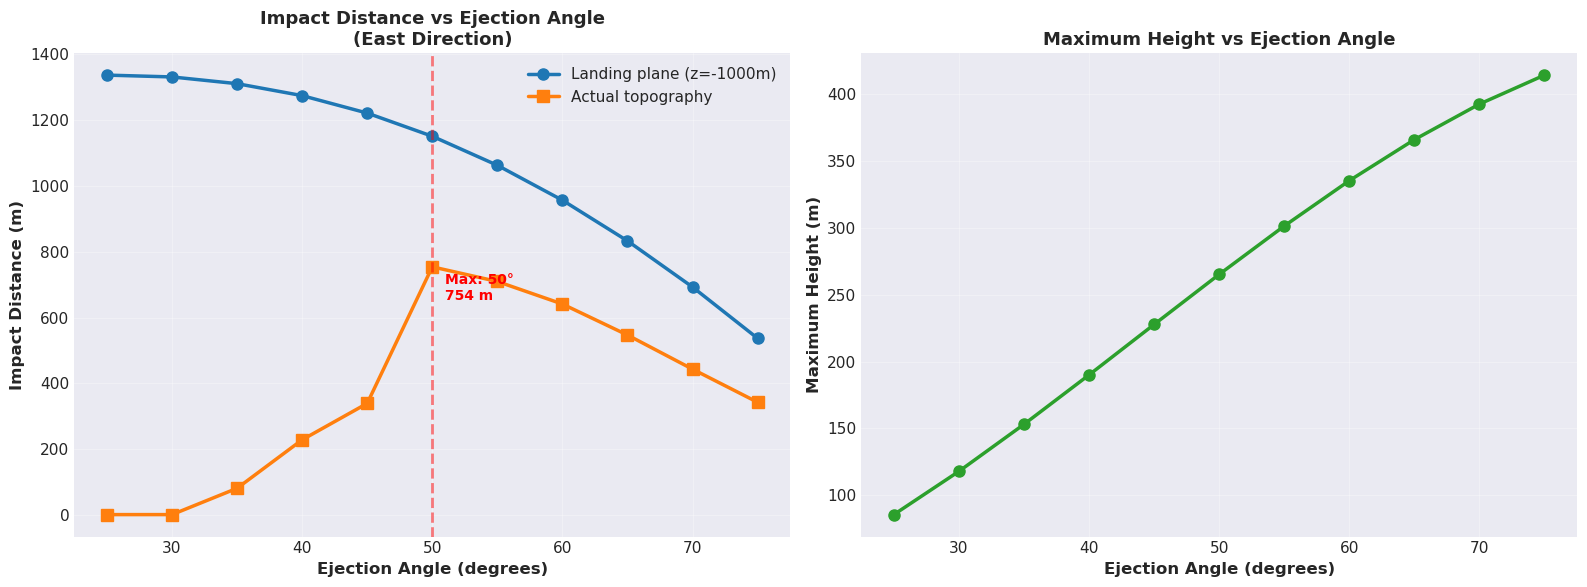


✓ Optimal ejection angle for maximum distance: 50°
  Maximum impact distance: 754.0 m


In [11]:
# Plot angle study results
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Distance vs angle
ax1.plot(angle_results['angle'], angle_results['landing_plane'], 
         'o-', linewidth=2.5, markersize=8, label='Landing plane (z=-1000m)', color='#1f77b4')
ax1.plot(angle_results['angle'], angle_results['topography'], 
         's-', linewidth=2.5, markersize=8, label='Actual topography', color='#ff7f0e')
ax1.set_xlabel('Ejection Angle (degrees)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Impact Distance (m)', fontsize=12, fontweight='bold')
ax1.set_title('Impact Distance vs Ejection Angle\n(East Direction)', 
              fontsize=13, fontweight='bold')
ax1.grid(True, alpha=0.3)
ax1.legend(fontsize=11)

# Find optimal angle for topography
optimal_idx = angle_results['topography'].idxmax()
optimal_angle = angle_results.loc[optimal_idx, 'angle']
optimal_distance = angle_results.loc[optimal_idx, 'topography']
ax1.axvline(x=optimal_angle, color='red', linestyle='--', alpha=0.5, linewidth=2)
ax1.text(optimal_angle + 1, optimal_distance - 100, 
         f'Max: {optimal_angle:.0f}°\n{optimal_distance:.0f} m',
         fontsize=10, fontweight='bold', color='red')

# Maximum height vs angle
ax2.plot(angle_results['angle'], angle_results['max_height'], 
         'o-', linewidth=2.5, markersize=8, color='#2ca02c')
ax2.set_xlabel('Ejection Angle (degrees)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Maximum Height (m)', fontsize=12, fontweight='bold')
ax2.set_title('Maximum Height vs Ejection Angle', fontsize=13, fontweight='bold')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\n✓ Optimal ejection angle for maximum distance: {optimal_angle:.0f}°")
print(f"  Maximum impact distance: {optimal_distance:.1f} m")

## Step 5: Multi-Direction Impact Map

Let's create a summary showing where projectiles with the same initial conditions would land in all four directions.

Impact distances in all directions:

Configuration        East       North      West       South     
----------------------------------------------------------------------
30°, 100 m/s                2 m         2 m         2 m       167 m
45°, 100 m/s              339 m       442 m       302 m       620 m
60°, 100 m/s              641 m       530 m       557 m       597 m


/tmp/ipykernel_13733/1389148629.py:73: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


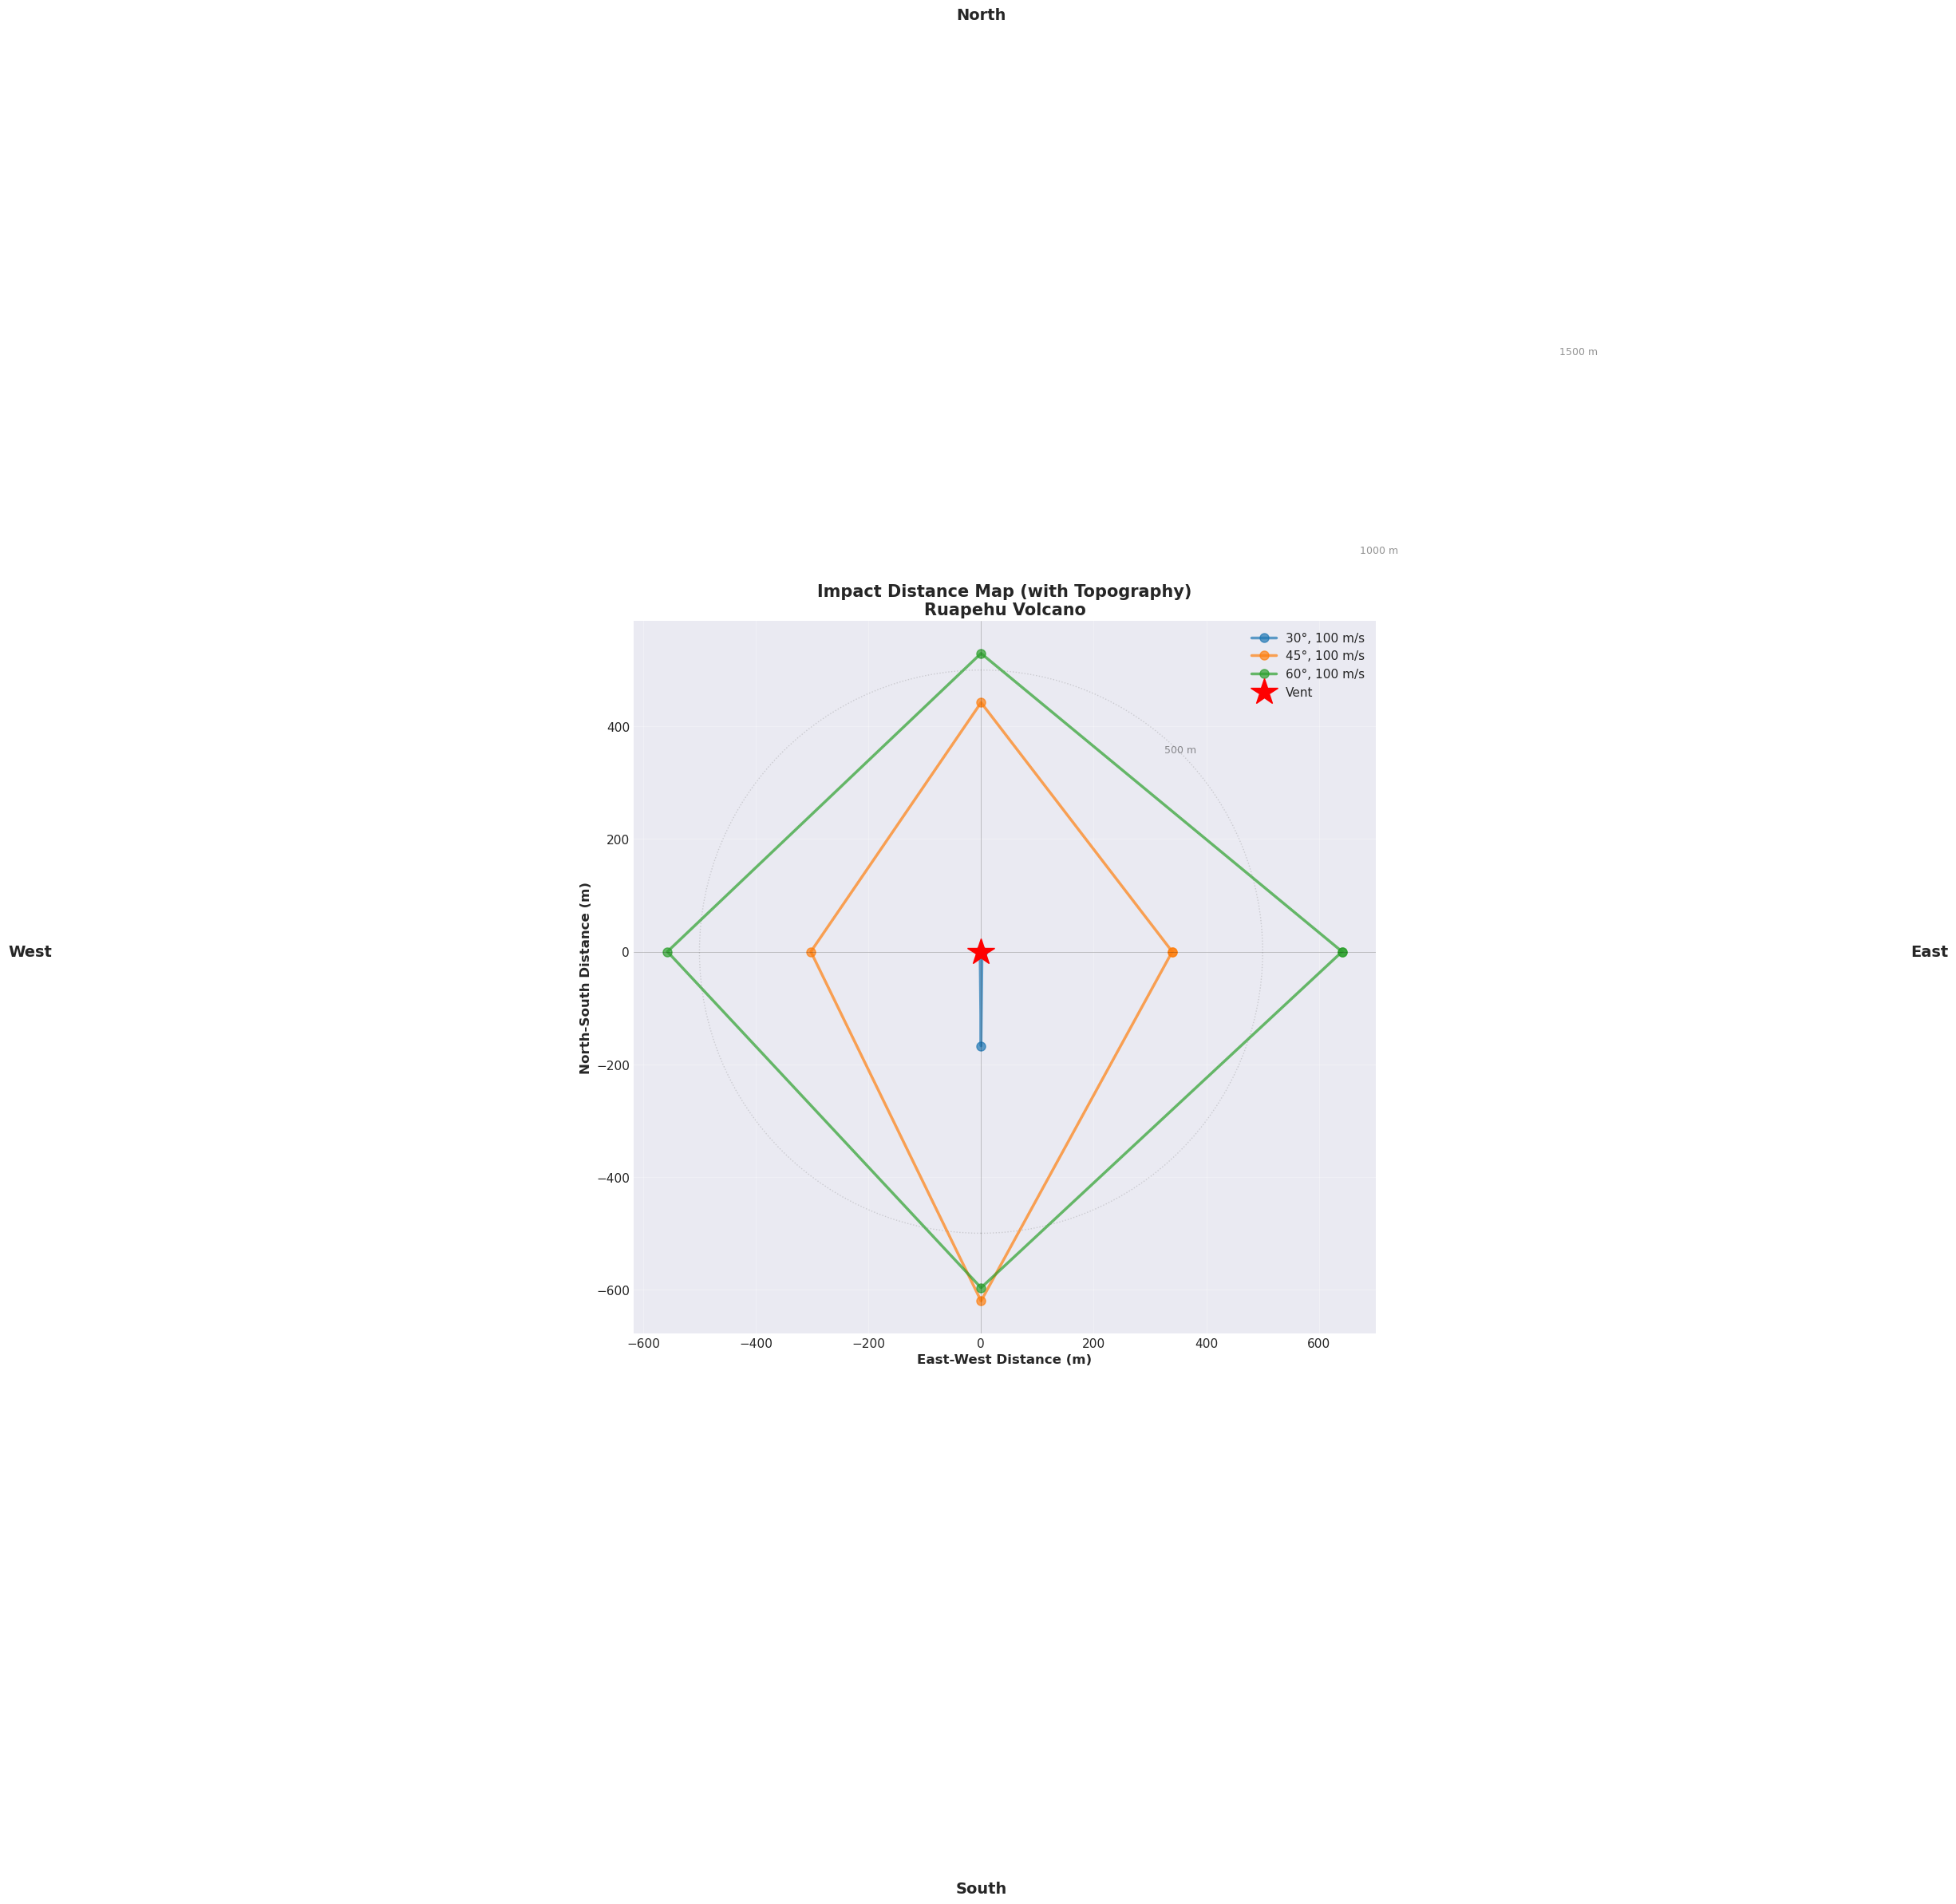


✓ Multi-direction impact map complete!


In [12]:
# Calculate trajectories for multiple parameter sets
test_configs = [
    {'angle': 30, 'velocity': 100, 'diameter': 0.5, 'label': '30°, 100 m/s'},
    {'angle': 45, 'velocity': 100, 'diameter': 0.5, 'label': '45°, 100 m/s'},
    {'angle': 60, 'velocity': 100, 'diameter': 0.5, 'label': '60°, 100 m/s'},
]

config_colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

# Create a polar-like summary
fig = plt.figure(figsize=(12, 12))
ax = fig.add_subplot(111)

# Direction angles for plotting
dir_angles = {'East': 0, 'North': 90, 'West': 180, 'South': 270}

print("Impact distances in all directions:\n")
print(f"{'Configuration':<20} {'East':<10} {'North':<10} {'West':<10} {'South':<10}")
print("-" * 70)

for config_idx, config in enumerate(test_configs):
    # Calculate trajectory
    traj = eject(config['angle'], config['velocity'], config['diameter'])
    traj_x = traj[:, 0]
    traj_z = traj[:, 1]
    
    impacts = {}
    
    # Find impacts in each direction
    for dir_name, data in directions.items():
        impact_x, impact_z = find_impact_point(traj_x, traj_z, data['x'], data['z'])
        impacts[dir_name] = impact_x
    
    print(f"{config['label']:<20} {impacts['East']:>8.0f} m  {impacts['North']:>8.0f} m  "
          f"{impacts['West']:>8.0f} m  {impacts['South']:>8.0f} m")
    
    # Plot on 2D map (simplified)
    x_coords = [impacts['East'], 0, -impacts['West'], 0, impacts['East']]
    y_coords = [0, impacts['North'], 0, -impacts['South'], 0]
    
    ax.plot(x_coords, y_coords, 'o-', linewidth=2.5, markersize=8,
            color=config_colors[config_idx], label=config['label'], alpha=0.7)

# Add vent at center
ax.plot(0, 0, 'r*', markersize=25, label='Vent', zorder=10)

# Add direction labels
max_dist = 1600
ax.text(max_dist + 50, 0, 'East', fontsize=14, fontweight='bold', ha='left', va='center')
ax.text(0, max_dist + 50, 'North', fontsize=14, fontweight='bold', ha='center', va='bottom')
ax.text(-max_dist - 50, 0, 'West', fontsize=14, fontweight='bold', ha='right', va='center')
ax.text(0, -max_dist - 50, 'South', fontsize=14, fontweight='bold', ha='center', va='top')

# Formatting
ax.set_xlabel('East-West Distance (m)', fontsize=12, fontweight='bold')
ax.set_ylabel('North-South Distance (m)', fontsize=12, fontweight='bold')
ax.set_title('Impact Distance Map (with Topography)\nRuapehu Volcano', 
             fontsize=15, fontweight='bold')
ax.grid(True, alpha=0.3)
ax.legend(fontsize=11, loc='upper right')
ax.set_aspect('equal')
ax.axhline(y=0, color='k', linewidth=0.5, alpha=0.3)
ax.axvline(x=0, color='k', linewidth=0.5, alpha=0.3)

# Add distance circles
for dist in [500, 1000, 1500]:
    circle = plt.Circle((0, 0), dist, fill=False, edgecolor='gray', 
                        linestyle=':', linewidth=1, alpha=0.3)
    ax.add_patch(circle)
    ax.text(dist/np.sqrt(2), dist/np.sqrt(2), f'{dist} m', 
            fontsize=9, alpha=0.5, ha='center')

plt.tight_layout()
plt.show()

print("\n✓ Multi-direction impact map complete!")

In [13]:
print("\n" + "="*70)
print("  Topography-Aware Ballistic Trajectory Analysis Complete!")
print("="*70)
print("\nThis notebook demonstrated:")
print("  ✓ Loading and visualizing topographic profiles")
print("  ✓ Calculating trajectory-topography intersections")
print("  ✓ Comparing landing plane vs actual topography impacts")
print("  ✓ Parameter studies with topographic constraints")
print("  ✓ Multi-directional impact mapping")
print("\nFor Monte Carlo simulations and probabilistic hazard assessment,")
print("use the distances() function to process multiple trajectories.")


  Topography-Aware Ballistic Trajectory Analysis Complete!

This notebook demonstrated:
  ✓ Loading and visualizing topographic profiles
  ✓ Calculating trajectory-topography intersections
  ✓ Comparing landing plane vs actual topography impacts
  ✓ Parameter studies with topographic constraints
  ✓ Multi-directional impact mapping

For Monte Carlo simulations and probabilistic hazard assessment,
use the distances() function to process multiple trajectories.
